Task 3.1

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm

In [12]:
# 1) Параметры
np.random.seed(42)

R = 2.0
N = 40
r = 0.1
a = 0.5
Y = 10000
E = 1.0
lambda_zat = 8.0
N_draws = 5000

p_geom = N * r**2 / (4 * R**2)
p_zat = np.exp(-R / lambda_zat)
Q_ozhid = a * Y * E * p_geom

print(f"Геометрическая вероятность: {p_geom:.4f}")
print(f"Вероятность выживания фотона: {p_zat:.4f}")

Геометрическая вероятность: 0.0250
Вероятность выживания фотона: 0.7788


In [13]:
# 2) Модель без затухания
with pm.Model() as model:
    N_hit = pm.Poisson('N_hit', mu=Y * E * p_geom)
    Q = pm.Poisson('Q', mu=N_hit * a)

In [14]:
# 3) Модель с затуханием
with pm.Model() as model_zat:
    N_hit_zat = pm.Poisson('N_hit_zat', mu=Y * E * p_geom * p_zat)
    Q_zat = pm.Poisson('Q_zat', mu=N_hit_zat * a)

In [15]:
# 4) MCMC без затухания
with model:
    trace = pm.sample(draws=N_draws, tune=1000, step=pm.Metropolis(),
                      chains=4, cores=1, random_seed=42, progressbar=False)

Q_mcmc = trace.posterior['Q'].values.flatten()

Sequential sampling (4 chains in 1 job)
CompoundStep
>Metropolis: [N_hit]
>Metropolis: [Q]
Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 4 seconds.


In [16]:
# 5) MCMC с затуханием
with model_zat:
    trace_zat = pm.sample(draws=N_draws, tune=1000, step=pm.Metropolis(),
                          chains=4, cores=1, random_seed=42, progressbar=False)

Q_mcmc_zat = trace_zat.posterior['Q_zat'].values.flatten()

Sequential sampling (4 chains in 1 job)
CompoundStep
>Metropolis: [N_hit_zat]
>Metropolis: [Q_zat]
Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 3 seconds.


In [17]:
# 6) Прямое моделирование
N_events = len(Q_mcmc)
N_photons = np.random.poisson(Y * E, N_events)
N_hit_direct = np.random.binomial(N_photons, p_geom)
Q_direct = np.random.poisson(N_hit_direct * a)

N_photons_zat = np.random.poisson(Y * E, N_events)
N_hit_direct_zat = np.random.binomial(N_photons_zat, p_geom * p_zat)
Q_direct_zat = np.random.poisson(N_hit_direct_zat * a)

In [18]:
# 7) Сравнение результатов
for name, Q_vals in [('Прямой MC', Q_direct),
                     ('PyMC MCMC', Q_mcmc),
                     ('Прямой MC с затуханием', Q_direct_zat),
                     ('PyMC MCMC с затуханием', Q_mcmc_zat)]:
    Q_mean = np.mean(Q_vals)
    Q_std = np.std(Q_vals)
    print(f"{name}: <Q> = {Q_mean:.2f}, sigma = {Q_std:.2f}, sigma/<Q> = {Q_std / Q_mean:.4f}")

print(f"Ожидаемый заряд без затухания: {Q_ozhid:.2f}")
print(f"Ожидаемый заряд с затуханием: {Q_ozhid * p_zat:.2f}")

Прямой MC: <Q> = 124.86, sigma = 13.74, sigma/<Q> = 0.1101
PyMC MCMC: <Q> = 125.48, sigma = 13.61, sigma/<Q> = 0.1084
Прямой MC с затуханием: <Q> = 97.38, sigma = 12.08, sigma/<Q> = 0.1241
PyMC MCMC с затуханием: <Q> = 97.70, sigma = 12.09, sigma/<Q> = 0.1238
Ожидаемый заряд без затухания: 125.00
Ожидаемый заряд с затуханием: 97.35


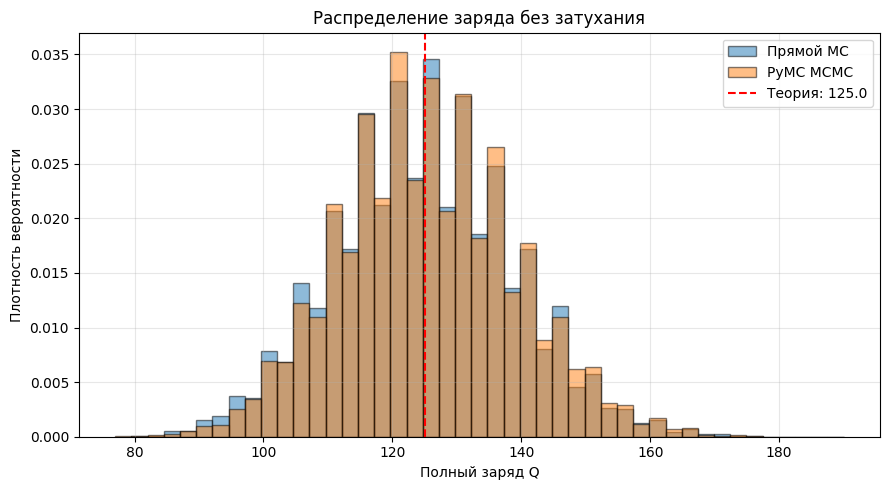

In [19]:
# 8) Распределение заряда без затухания
bins = np.histogram_bin_edges(np.concatenate([Q_direct, Q_mcmc]), bins=45)

plt.figure(figsize=(9, 5))
plt.hist(Q_direct, bins=bins, density=True, alpha=0.5, edgecolor='black', label='Прямой MC')
plt.hist(Q_mcmc, bins=bins, density=True, alpha=0.5, edgecolor='black', label='PyMC MCMC')
plt.axvline(Q_ozhid, color='red', linestyle='--', label=f'Теория: {Q_ozhid:.1f}')
plt.xlabel('Полный заряд Q')
plt.ylabel('Плотность вероятности')
plt.title('Распределение заряда без затухания')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

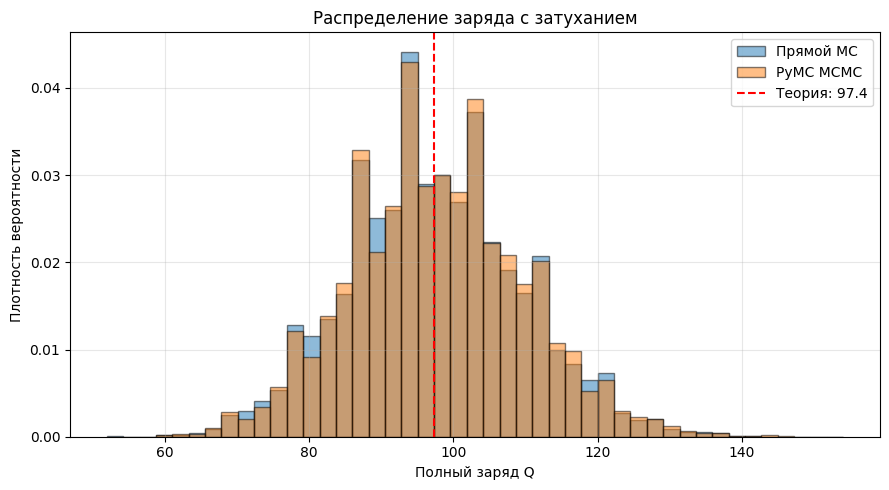

In [20]:
# 9) Распределение заряда с затуханием
bins_zat = np.histogram_bin_edges(np.concatenate([Q_direct_zat, Q_mcmc_zat]), bins=45)

plt.figure(figsize=(9, 5))
plt.hist(Q_direct_zat, bins=bins_zat, density=True, alpha=0.5, edgecolor='black', label='Прямой MC')
plt.hist(Q_mcmc_zat, bins=bins_zat, density=True, alpha=0.5, edgecolor='black', label='PyMC MCMC')
plt.axvline(Q_ozhid * p_zat, color='red', linestyle='--', label=f'Теория: {Q_ozhid * p_zat:.1f}')
plt.xlabel('Полный заряд Q')
plt.ylabel('Плотность вероятности')
plt.title('Распределение заряда с затуханием')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()